# Notebook 15 — Final 2024 Test Evaluation
## Dengue Disease Prediction | One-month-ahead forecasting

**Research question:** How accurately does the *preselected* LSTM forecast district-level monthly dengue cases in the previously untouched year 2024?

### Learning objectives
1. Select **one** saved model using only the 2022–2023 validation results from Notebooks 13–14.
2. Freeze the model choice **before** loading the 2024 labels.
3. Evaluate the selected, previously trained model on the 2024 test set **once**.
4. Examine errors by district and month; save auditable tables, figures, and a JSON evaluation report.

**No retraining, no rescaling, no hyperparameter tuning, no 2024-driven model selection.** The models use a weather-only feature set; population-inclusive experiments require a separate explicitly designed comparison.

## 1. Experimental protocol and interpretation

| Stage | Forecast target dates | Role |
|---|---|---|
| Train | Through December 2021 | Fit model parameters and the StandardScaler (Notebook 12) |
| Validation | January 2022–December 2023 | Select baseline versus GWO model using MAE in case units |
| Test | January–December 2024 | Estimate generalization of the **already selected** model |

**Important:** Each observation is a six-month sequence ending in month *t*, predicting dengue in *t+1*. The model has already been fitted. The target is the proportional monthly allocation of weekly case counts, so targets may be fractional; do not round before evaluating.

The validation set has been reused for GWO search and selection, so its metrics may be optimistic. The 2024 test is the independent evaluation. Re-running the test repeatedly to change choices would compromise that independence.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

SEED = 42
np.random.seed(SEED)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "final" / "model_inputs").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/final/model_inputs. Open the Dengue_Project folder in VS Code and run Notebook 12 first.")
INPUT_DIR = ROOT / "data" / "final" / "model_inputs"
MODEL_DIR = ROOT / "models"
METRIC_DIR = ROOT / "results" / "metrics"
TABLE_DIR = ROOT / "results" / "tables"
FIG_DIR = ROOT / "results" / "figures"
for directory in (METRIC_DIR, TABLE_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: d:\Dengue_Project


## 2. Select the final model using validation evidence only

**Selection rule (declared before looking at test):** Select the saved model with the smaller **validation MAE**. A tie goes to the simpler fixed LSTM. This compares the original-case-unit validation scores, not training loss. We require that both files identify the **weather-only** dataset and validation-only metrics.

Why MAE? It is the average absolute difference between predicted and observed monthly dengue cases; a lower value means fewer cases of average error. GWO optimized validation MAE, so this selection metric is aligned with the experiment. RMSE will also be reported on test as a complementary metric.

In [2]:
baseline_file = METRIC_DIR / "notebook13_validation_metrics.json"
gwo_file = METRIC_DIR / "notebook14_validation_metrics.json"
baseline_model = MODEL_DIR / "notebook13_fixed_lstm_weather_only.keras"
gwo_model = MODEL_DIR / "notebook14_gwo_lstm_weather_only.keras"
required = [baseline_file, gwo_file, baseline_model, gwo_model,
            MODEL_DIR / "notebook13_fixed_lstm_config.json",
            MODEL_DIR / "notebook14_gwo_search_manifest.json"]
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing saved Notebook 13/14 artifacts. Run those notebooks first:\n" + "\n".join(missing))
base = json.loads(baseline_file.read_text(encoding="utf-8"))
gwo = json.loads(gwo_file.read_text(encoding="utf-8"))
base_config = json.loads((MODEL_DIR / "notebook13_fixed_lstm_config.json").read_text(encoding="utf-8"))
gwo_manifest = json.loads((MODEL_DIR / "notebook14_gwo_search_manifest.json").read_text(encoding="utf-8"))
assert base.get("validation_only") is True and gwo.get("validation_only") is True
assert base.get("dataset") == gwo.get("dataset") == base_config.get("variant") == "weather_only"
assert gwo_manifest.get("test_accessed") is False
scores = pd.DataFrame([
    {"model": "fixed_lstm", "validation_MAE_cases": float(base["metrics"]["MAE_cases"]),
     "validation_RMSE_cases": float(base["metrics"]["RMSE_cases"]), "model_path": str(baseline_model)},
    {"model": "gwo_lstm", "validation_MAE_cases": float(gwo["metrics"]["MAE_cases"]),
     "validation_RMSE_cases": float(gwo["metrics"]["RMSE_cases"]), "model_path": str(gwo_model)},
])
assert np.isfinite(scores[["validation_MAE_cases", "validation_RMSE_cases"]].to_numpy()).all()
# Stable tie-break: fixed_lstm is the first row.
selected = scores.sort_values("validation_MAE_cases", kind="stable").iloc[0]
selected_name = str(selected["model"])
selected_path = Path(selected["model_path"])
print("SELECTED BEFORE OPENING 2024 TEST DATA:", selected_name)
display(scores)

SELECTED BEFORE OPENING 2024 TEST DATA: gwo_lstm


,model,validation_MAE_cases,validation_RMSE_cases,model_path
0,fixed_lstm,89.078628,177.532125,d:\Dengue_Project\models\notebook13_fixed_lstm...
1,gwo_lstm,85.064860,178.239409,d:\Dengue_Project\models\notebook14_gwo_lstm_w...


### Why save the selection decision first?

The following file records the chosen model and selection criterion **before any 2024 targets are loaded**. Notebook 16 will read this decision, ensuring explanations refer to the exact final model. **Do not edit the decision after inspecting test errors.**

In [3]:
selection_manifest = {
    "dataset": "weather_only",
    "selected_model": selected_name,
    "selected_model_path": str(selected_path.relative_to(ROOT)),
    "selection_metric": "validation_MAE_cases",
    "selection_period": "2022-01_to_2023-12",
    "selection_rule": "minimum_validation_MAE_tie_fixed_lstm",
    "validation_scores": scores.drop(columns="model_path").to_dict(orient="records"),
    "test_used_for_selection": False,
    "training_protocol": "saved_NB13_or_NB14_model_no_retraining",
    "target_transform": "log1p_cases_inverse_expm1",
    "sequence_length": 6,
}
selection_path = MODEL_DIR / "notebook15_final_model_selection.json"
selection_path.write_text(json.dumps(selection_manifest, indent=2), encoding="utf-8")
print("Selection manifest saved:", selection_path.relative_to(ROOT))

Selection manifest saved: models\notebook15_final_model_selection.json


## 3. Load the saved selected model

Keras `.keras` files store the trained network and its learned weights. **Loading** a model is not training it. We will check the expected six-month input shape and feature order against Notebook 12's scaler metadata.

In [4]:
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError("Install TensorFlow in the active .venv: python -m pip install tensorflow") from exc
model = tf.keras.models.load_model(selected_path, compile=False)
scaler_info = json.loads((INPUT_DIR / "weather_only_scaler.json").read_text(encoding="utf-8"))
assert scaler_info["fit_partition"] == "train_only"
assert scaler_info["sequence_length"] == 6
print("TensorFlow:", tf.__version__)
print("Model:", selected_path.name)
print("Input shape:", model.input_shape)
print("Number of predictors:", len(scaler_info["feature_names"]))

TensorFlow: 2.21.0
Model: notebook14_gwo_lstm_weather_only.keras
Input shape: (None, 6, 33)
Number of predictors: 33


## 4. Open the previously untouched 2024 test partition

The `.npz` file holds `X` (scaled six-month input sequences), `y_raw` (observed allocated cases), `y_log1p`, and the ordered feature names. A separate metadata CSV maps each prediction to a district and target month. We check alignment and the exact 2024 coverage before evaluating.

In [5]:
test_file = INPUT_DIR / "weather_only_test.npz"
metadata_file = INPUT_DIR / "weather_only_test_metadata.csv"
with np.load(test_file, allow_pickle=False) as pack:
    X_test = pack["X"].astype(np.float32)
    y_test = pack["y_raw"].astype(np.float64)
    y_test_log = pack["y_log1p"].astype(np.float64)
    names = pack["feature_names"].tolist()
meta = pd.read_csv(metadata_file, parse_dates=["target_date", "feature_date", "sequence_start_date"])
assert len(X_test) == len(y_test) == len(meta) == 300
assert X_test.shape[1:] == (6, len(names))
assert list(names) == list(scaler_info["feature_names"])
assert model.input_shape[-2:] == X_test.shape[1:]
assert meta["partition"].eq("test").all()
assert meta["target_date"].dt.year.eq(2024).all()
assert meta["administrative_district"].nunique() == 25
assert meta.groupby("administrative_district")["target_date"].nunique().eq(12).all()
assert (meta["target_date"] == meta["feature_date"] + pd.offsets.MonthBegin(1)).all()
assert np.isfinite(X_test).all() and np.isfinite(y_test).all()
assert np.all(y_test >= 0)
assert np.allclose(np.log1p(y_test), y_test_log, atol=1e-4)
print("Test X:", X_test.shape, "| y:", y_test.shape)
display(meta[["administrative_district", "feature_date", "target_date"]].head())

Test X: (300, 6, 33) | y: (300,)


,administrative_district,feature_date,target_date
0,Ampara,2023-12-01,2024-01-01
1,Ampara,2024-01-01,2024-02-01
2,Ampara,2024-02-01,2024-03-01
3,Ampara,2024-03-01,2024-04-01
4,Ampara,2024-04-01,2024-05-01


## 5. Predict dengue cases and calculate test metrics

The LSTM outputs predictions on the `log1p(cases)` scale. To return to dengue case units, apply `expm1` and clip negative predictions to zero. The original cases are proportional allocations of weekly surveillance counts, so they can be non-integers.

Metrics:

- **MAE** = mean absolute error, in cases; lower is better.
- **RMSE** = square root of mean squared error, in cases; penalizes large outbreak misses more.
- **WAPE** = sum absolute errors / sum observed cases × 100; undefined if total observed cases are zero.
- **Bias** = mean(predicted − observed), in cases; positive = overprediction.
- **R²** = fraction of variance explained; may be negative.

Metrics are **descriptive**, not uncertainty intervals. A single year cannot prove future deployment performance.

In [6]:
def to_case_units(predicted_log):
    z = np.asarray(predicted_log, dtype=np.float64).reshape(-1)
    return np.maximum(0.0, np.expm1(np.clip(z, -20.0, 20.0)))

def evaluate(y_true, y_pred):
    a = np.asarray(y_true, dtype=float).reshape(-1)
    p = np.asarray(y_pred, dtype=float).reshape(-1)
    assert len(a) == len(p) and len(a) > 0
    abs_error = np.abs(a - p)
    denominator = float(a.sum())
    return {
        "n_samples": int(len(a)),
        "MAE_cases": float(mean_absolute_error(a, p)),
        "RMSE_cases": float(np.sqrt(mean_squared_error(a, p))),
        "median_absolute_error_cases": float(np.median(abs_error)),
        "bias_pred_minus_actual_cases": float(np.mean(p - a)),
        "WAPE_percent": float(100 * abs_error.sum() / denominator) if denominator > 0 else None,
        "R2": float(r2_score(a, p)) if len(a) > 1 else None,
    }

pred_log = model.predict(X_test, batch_size=32, verbose=0)
pred_cases = to_case_units(pred_log)
assert np.isfinite(pred_cases).all()
test_metrics = evaluate(y_test, pred_cases)
print("2024 FINAL TEST METRICS (selected model only):")
for key, value in test_metrics.items():
    print(f"  {key}: {value}")

2024 FINAL TEST METRICS (selected model only):
  n_samples: 300
  MAE_cases: 69.52416372278867
  RMSE_cases: 154.60478716047163
  median_absolute_error_cases: 25.35355792477267
  bias_pred_minus_actual_cases: -41.84009353160056
  WAPE_percent: 41.691865467498474
  R2: 0.6969538054640181


## 6. Auditable predictions and district/month breakdown

Aggregate district-level errors separately from the overall test error. A district with only 12 test months can have an unstable error estimate. We therefore report the sample count and avoid interpreting the ranking as a definitive public-health ranking.

In [7]:
predictions = meta[["administrative_district", "feature_date", "target_date"]].copy()
predictions["actual_cases"] = y_test
predictions["predicted_cases"] = pred_cases
predictions["absolute_error_cases"] = np.abs(y_test - pred_cases)
predictions["signed_error_cases"] = pred_cases - y_test
predictions = predictions.sort_values(["target_date", "administrative_district"]).reset_index(drop=True)
district_results = pd.DataFrame([
    {"administrative_district": district, **evaluate(group["actual_cases"], group["predicted_cases"])}
    for district, group in predictions.groupby("administrative_district", sort=True)
]).sort_values("MAE_cases", ascending=False).reset_index(drop=True)
monthly_results = pd.DataFrame([
    {"target_date": date, **evaluate(group["actual_cases"], group["predicted_cases"]),
     "total_actual_cases": float(group["actual_cases"].sum()),
     "total_predicted_cases": float(group["predicted_cases"].sum())}
    for date, group in predictions.groupby("target_date", sort=True)
])
assert len(district_results) == 25 and len(monthly_results) == 12
assert district_results["n_samples"].eq(12).all()
assert monthly_results["n_samples"].eq(25).all()
print("Highest-error districts (descriptive):")
display(district_results.head(10).round(3))
print("Monthly test summary:")
display(monthly_results.round(3))

Highest-error districts (descriptive):


,administrative_district,n_samples,MAE_cases,RMSE_cases,median_absolute_error_cases,bias_pred_minus_actual_cases,WAPE_percent,R2
0,Colombo,12,464.587,506.494,420.378,-464.587,49.501,-0.453
1,Jaffna,12,232.462,461.569,64.003,-232.462,51.658,0.676
2,Kandy,12,151.435,187.045,124.183,-53.447,41.242,-0.395
3,Gampaha,12,130.132,139.291,129.875,-87.189,28.725,-0.042
4,Ratnapura,12,105.554,135.947,77.691,21.822,46.925,-3.417
5,Kalutara,12,63.480,108.815,35.401,4.607,28.552,-0.308
6,Kurunegala,12,59.931,81.670,32.999,19.000,36.254,0.523
7,Kegalle,12,55.621,68.747,52.365,-13.694,34.246,0.432
8,Matale,12,47.766,63.735,33.352,6.904,55.619,-1.255
9,Batticaloa,12,46.533,77.320,26.348,-43.469,35.242,0.607


Monthly test summary:


C:\Users\Abhimani\AppData\Local\Temp\ipykernel_8868\3506457284.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_results.round(3))


,target_date,n_samples,MAE_cases,RMSE_cases,median_absolute_error_cases,bias_pred_minus_actual_cases,WAPE_percent,R2,total_actual_cases,total_predicted_cases
0,2024-01-01,25,199.187,372.027,95.588,-104.877,42.860,0.653,11618.429,8996.513
1,2024-02-01,25,87.419,191.544,24.218,-51.816,33.136,0.618,6595.429,5300.027
2,2024-03-01,25,63.389,112.700,32.344,-51.057,42.512,0.494,3727.714,2451.296
3,2024-04-01,25,45.307,81.295,12.104,-38.678,49.143,0.380,2304.857,1337.918
4,2024-05-01,25,59.743,109.901,19.710,-56.098,56.624,0.283,2637.714,1235.266
5,2024-06-01,25,40.052,89.732,17.327,-2.374,31.867,0.768,3142.143,3082.789
6,2024-07-01,25,59.265,130.474,16.364,-19.765,33.696,0.794,4397.000,3902.864
7,2024-08-01,25,74.313,149.964,26.346,-66.839,46.755,0.631,3973.571,2302.588
8,2024-09-01,25,51.783,100.504,26.807,-47.256,43.969,0.651,2944.286,1762.875
9,2024-10-01,25,51.954,97.971,19.176,-46.776,43.116,0.632,3012.429,1843.030


## 7. Plot 2024 test predictions

**Figure 1:** Island-wide monthly sums of district predictions versus observed allocations. This aggregate plot can hide district-specific failures, so it must be interpreted alongside the district error table.

**Figure 2:** Observed versus predicted district-month cases; the dashed diagonal is perfect prediction.

**Figure 3:** District MAE; each bar is based on 12 test months.

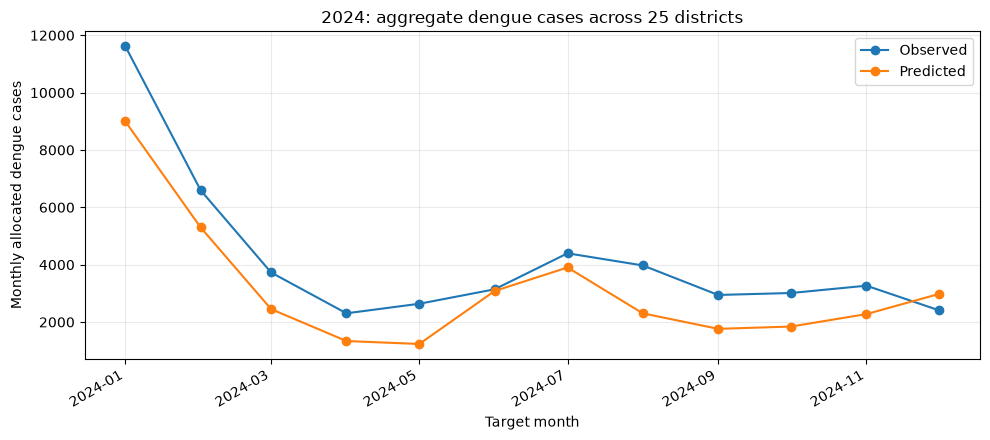

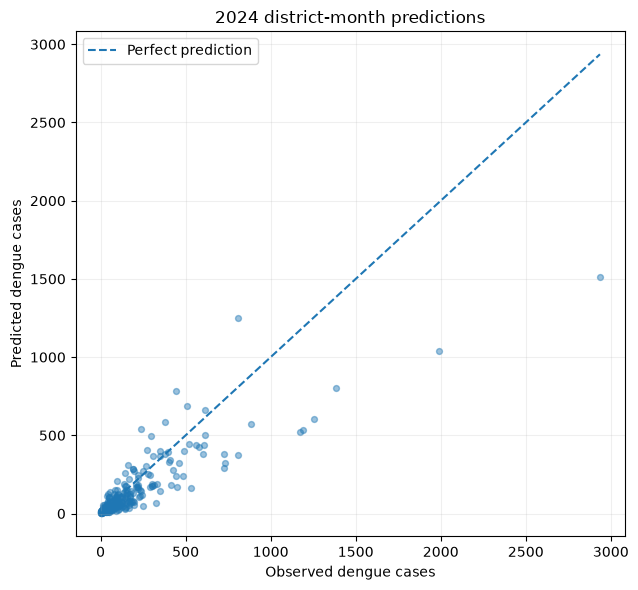

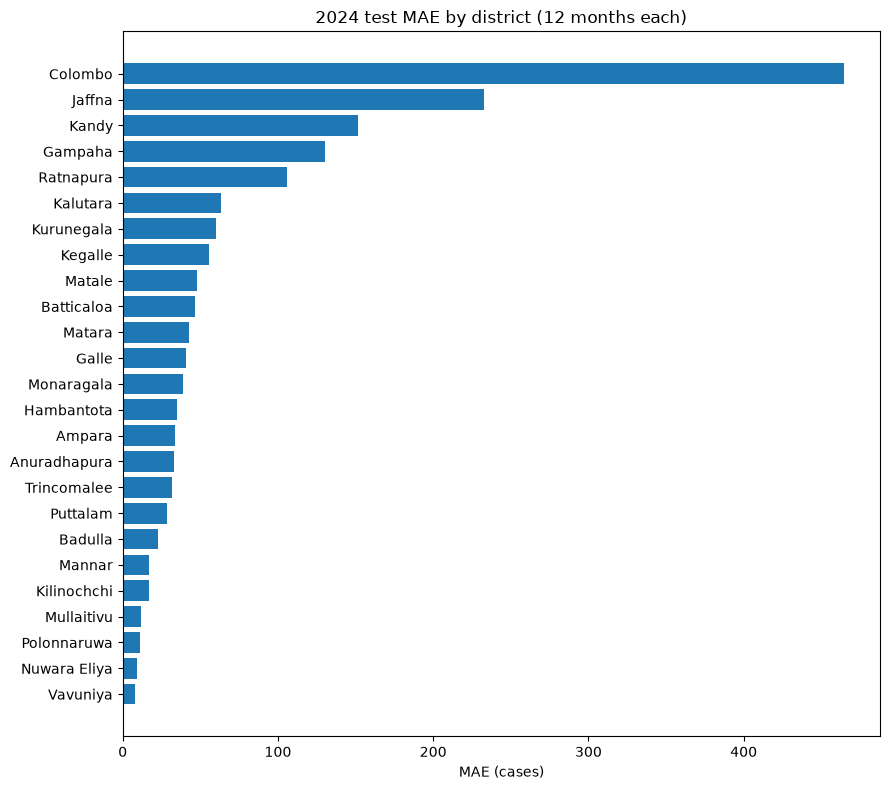

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly_results["target_date"], monthly_results["total_actual_cases"], marker="o", label="Observed")
ax.plot(monthly_results["target_date"], monthly_results["total_predicted_cases"], marker="o", label="Predicted")
ax.set(title="2024: aggregate dengue cases across 25 districts", xlabel="Target month", ylabel="Monthly allocated dengue cases")
ax.grid(alpha=0.25); ax.legend(); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(FIG_DIR / "notebook15_2024_monthly_actual_vs_predicted.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred_cases, alpha=0.45, s=18)
limit = float(max(y_test.max(), pred_cases.max()))
ax.plot([0, limit], [0, limit], linestyle="--", label="Perfect prediction")
ax.set(xlabel="Observed dengue cases", ylabel="Predicted dengue cases", title="2024 district-month predictions")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(FIG_DIR / "notebook15_2024_prediction_scatter.png", dpi=160)
plt.show()

ordered = district_results.sort_values("MAE_cases", ascending=True)
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(ordered["administrative_district"], ordered["MAE_cases"])
ax.set(xlabel="MAE (cases)", title="2024 test MAE by district (12 months each)")
fig.tight_layout()
fig.savefig(FIG_DIR / "notebook15_2024_district_mae.png", dpi=160)
plt.show()

## 8. Save reproducible research outputs

- `models/notebook15_final_model_selection.json` — frozen validation-only decision (already written).
- `results/metrics/notebook15_final_test_metrics.json` — independent 2024 test report.
- `results/tables/notebook15_2024_predictions.csv` — one row per district-month.
- `results/tables/notebook15_2024_district_metrics.csv` — 25 district summaries.
- `results/tables/notebook15_2024_monthly_metrics.csv` — 12 monthly summaries.
- `results/tables/notebook15_validation_selection.csv` — evidence used for selection.
- Three PNG figures under `results/figures/`.

Model files under `models/` may be large; check size before deciding whether to push them to GitHub.

In [9]:
report = {
    "selected_model": selected_name,
    "selected_model_path": str(selected_path.relative_to(ROOT)),
    "dataset": "weather_only",
    "selection_source": "validation_2022_2023_only",
    "test_period": "2024-01_to_2024-12",
    "test_sample_count": int(len(y_test)),
    "districts": 25,
    "test_metrics": test_metrics,
    "test_used_for_model_selection": False,
    "notes": ["No retraining or scaler fitting performed in Notebook 15.",
              "2024 test labels were loaded only after saving the validation-based selection.",
              "Targets are proportional monthly allocations of weekly surveillance cases."],
}
(METRIC_DIR / "notebook15_final_test_metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
predictions.to_csv(TABLE_DIR / "notebook15_2024_predictions.csv", index=False)
district_results.to_csv(TABLE_DIR / "notebook15_2024_district_metrics.csv", index=False)
monthly_results.to_csv(TABLE_DIR / "notebook15_2024_monthly_metrics.csv", index=False)
scores.drop(columns="model_path").to_csv(TABLE_DIR / "notebook15_validation_selection.csv", index=False)
assert selection_path.exists() and (METRIC_DIR / "notebook15_final_test_metrics.json").exists()
assert predictions[["actual_cases", "predicted_cases"]].notna().all().all()
print("ALL NOTEBOOK 15 CHECKS PASSED — 2024 independent test evaluated.")

ALL NOTEBOOK 15 CHECKS PASSED — 2024 independent test evaluated.


## 9. Research interpretation checklist

After running this notebook on your real data, report the **actual numerical results** (do not copy hypothetical numbers):

1. Which model was selected using **validation MAE** and why?
2. What are the selected model's 2024 test MAE, RMSE, WAPE, and bias?
3. Which districts and months have the largest errors?
4. Did the model systematically miss major outbreaks? Review large residuals.
5. Limitations: proportional weekly-to-monthly case allocation, incomplete weather coverage at the outer boundary, annual population unavailable before 2014, single test year, and noncausal weather relationships.

**Do not change Notebook 13/14 hyperparameters after seeing these results and still call this an untouched test.** Notebook 16 will explain the frozen model using the **validation partition**.